# **Machine Learning Experiment Number 9**


**Name:** Om Milind Retharekar   
           
**Roll no.:** CS46

**Class:** BE CSE

**Batch:** CS 03

### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

# Load the dataset
df = pd.read_csv("palmerpenguins_extended.csv")

# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [12]:
# 1) Missing values
print("Missing values per column:")
print(df.isnull().sum())

# This extended dataset uses 'bill_*' names for what the manual calls 'culmen_*'
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
target = "species"

# Drop rows with missing values in the columns we use (none are missing here, but kept for safety)
df_clean = df.dropna(subset=features + [target]).reset_index(drop=True)
print("\nRows after cleaning:", len(df_clean))

# 2) Features (X) and target (y)
X = df_clean[features]
y = df_clean[target]

# 3) Encode the species labels
le = LabelEncoder()
y_enc = le.fit_transform(y)
class_names = le.classes_
print("\nClass encoding:", dict(zip(class_names, range(len(class_names)))))

Missing values per column:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
diet                 0
life_stage           0
health_metrics       0
year                 0
dtype: int64

Rows after cleaning: 3430

Class encoding: {'Adelie': 0, 'Chinstrap': 1, 'Gentoo': 2}


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, random_state=42, stratify=y_enc
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (2744, 4)
Testing set : (686, 4)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [14]:
# CART classifier with the Gini criterion.
# max_depth=4 keeps the tree readable and limits overfitting.
cart = DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=42)
cart.fit(X_train, y_train)
y_pred_cart = cart.predict(X_test)

print("Tree depth :", cart.get_depth())
print("Leaf nodes :", cart.get_n_leaves())

# Objective 4: compare impurity measures (Gini vs Entropy) and tree depth
print("\nImpurity measure comparison (test accuracy):")
for crit in ["gini", "entropy"]:
    for depth in [3, 4, 5, None]:
        m = DecisionTreeClassifier(criterion=crit, max_depth=depth, random_state=42).fit(X_train, y_train)
        print(f"  criterion={crit:8s} max_depth={str(depth):4s} -> accuracy = {accuracy_score(y_test, m.predict(X_test)):.4f}")

# Feature importances of the main model
imp = pd.Series(cart.feature_importances_, index=features).sort_values(ascending=False)
print("\nFeature importances:")
print(imp.round(4))

Tree depth : 4
Leaf nodes : 16

Impurity measure comparison (test accuracy):
  criterion=gini     max_depth=3    -> accuracy = 0.5641
  criterion=gini     max_depth=4    -> accuracy = 0.5671
  criterion=gini     max_depth=5    -> accuracy = 0.5554
  criterion=gini     max_depth=None -> accuracy = 0.4519
  criterion=entropy  max_depth=3    -> accuracy = 0.5641
  criterion=entropy  max_depth=4    -> accuracy = 0.5627
  criterion=entropy  max_depth=5    -> accuracy = 0.5612
  criterion=entropy  max_depth=None -> accuracy = 0.4592

Feature importances:
bill_depth_mm        0.5430
body_mass_g          0.2722
bill_length_mm       0.1808
flipper_length_mm    0.0040
dtype: float64


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Accuracy: 0.5671

Confusion Matrix:
 [[209   2 101]
 [ 66   3  56]
 [ 68   4 177]]

Classification Report:

              precision    recall  f1-score   support

      Adelie       0.61      0.67      0.64       312
   Chinstrap       0.33      0.02      0.04       125
      Gentoo       0.53      0.71      0.61       249

    accuracy                           0.57       686
   macro avg       0.49      0.47      0.43       686
weighted avg       0.53      0.57      0.52       686



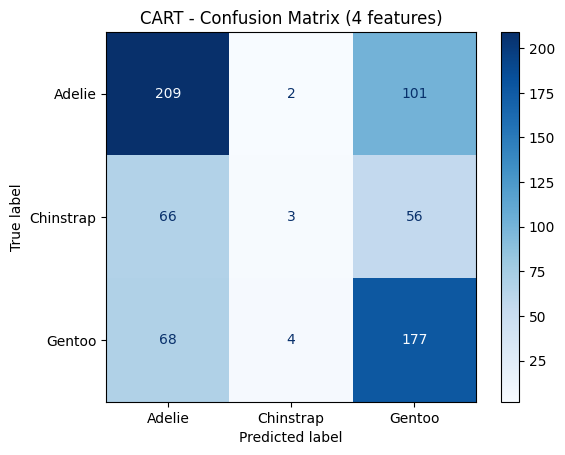

In [15]:
acc_cart = accuracy_score(y_test, y_pred_cart)
cm_cart = confusion_matrix(y_test, y_pred_cart)

print(f"CART Accuracy: {acc_cart:.4f}\n")
print("Confusion Matrix:\n", cm_cart)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_cart, target_names=class_names))

ConfusionMatrixDisplay(cm_cart, display_labels=class_names).plot(cmap="Blues")
plt.title("CART - Confusion Matrix (4 features)")
plt.show()

# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


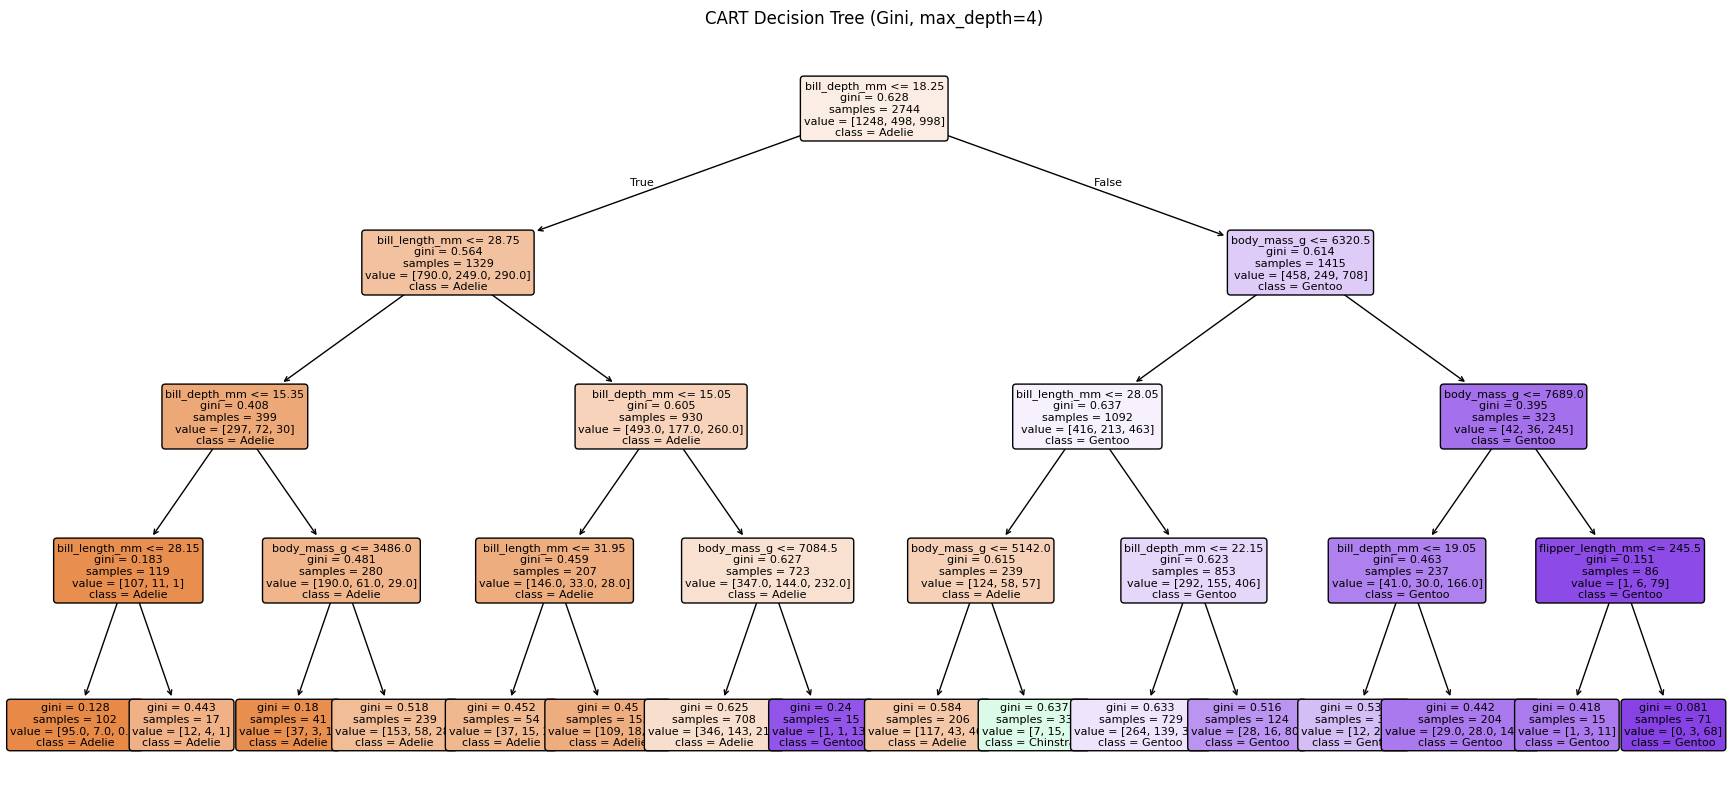

2-D CART test accuracy: 0.5131


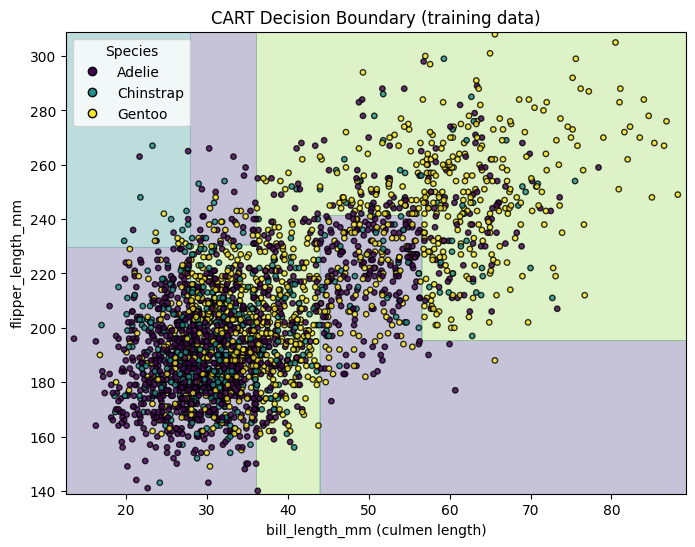

In [16]:
# (a) Tree structure
plt.figure(figsize=(22, 10))
plot_tree(cart, feature_names=features, class_names=list(class_names),
          filled=True, rounded=True, fontsize=8)
plt.title("CART Decision Tree (Gini, max_depth=4)")
plt.show()

# (b) 2-D features
feat2 = ["bill_length_mm", "flipper_length_mm"]
X2 = df_clean[feat2].values
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y_enc, test_size=0.2, random_state=42, stratify=y_enc
)

cart2 = DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=42)
cart2.fit(X2_train, y2_train)
print("2-D CART test accuracy:", round(accuracy_score(y2_test, cart2.predict(X2_test)), 4))

# Helper to draw decision regions + data points
def plot_boundary(model, X, y, ax, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="viridis", levels=np.arange(len(class_names) + 1) - 0.5)
    sc = ax.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", edgecolor="k", s=15, alpha=0.8)
    ax.set_xlabel("bill_length_mm (culmen length)")
    ax.set_ylabel("flipper_length_mm")
    ax.set_title(title)
    handles = [plt.Line2D([], [], marker="o", ls="", color=sc.cmap(sc.norm(i)), markeredgecolor="k", label=n)
               for i, n in enumerate(class_names)]
    ax.legend(handles=handles, title="Species")

fig, ax = plt.subplots(figsize=(8, 6))
plot_boundary(cart2, X2_train, y2_train, ax, "CART Decision Boundary (training data)")
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

Logistic Regression (2-D) test accuracy: 0.5262


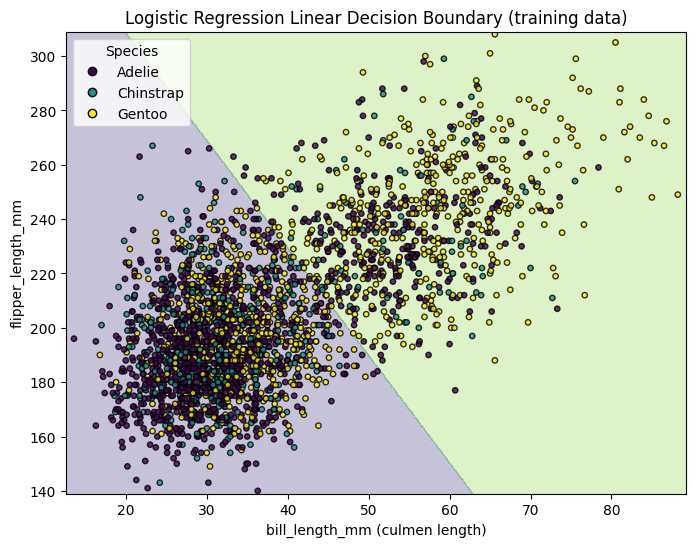

In [17]:
# Linear baseline: Logistic Regression on the same two features
# (scaling helps the solver converge; the boundary stays linear)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
logreg.fit(X2_train, y2_train)
y_pred_lr = logreg.predict(X2_test)
print("Logistic Regression (2-D) test accuracy:", round(accuracy_score(y2_test, y_pred_lr), 4))

fig, ax = plt.subplots(figsize=(8, 6))
plot_boundary(logreg, X2_train, y2_train, ax, "Logistic Regression Linear Decision Boundary (training data)")
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

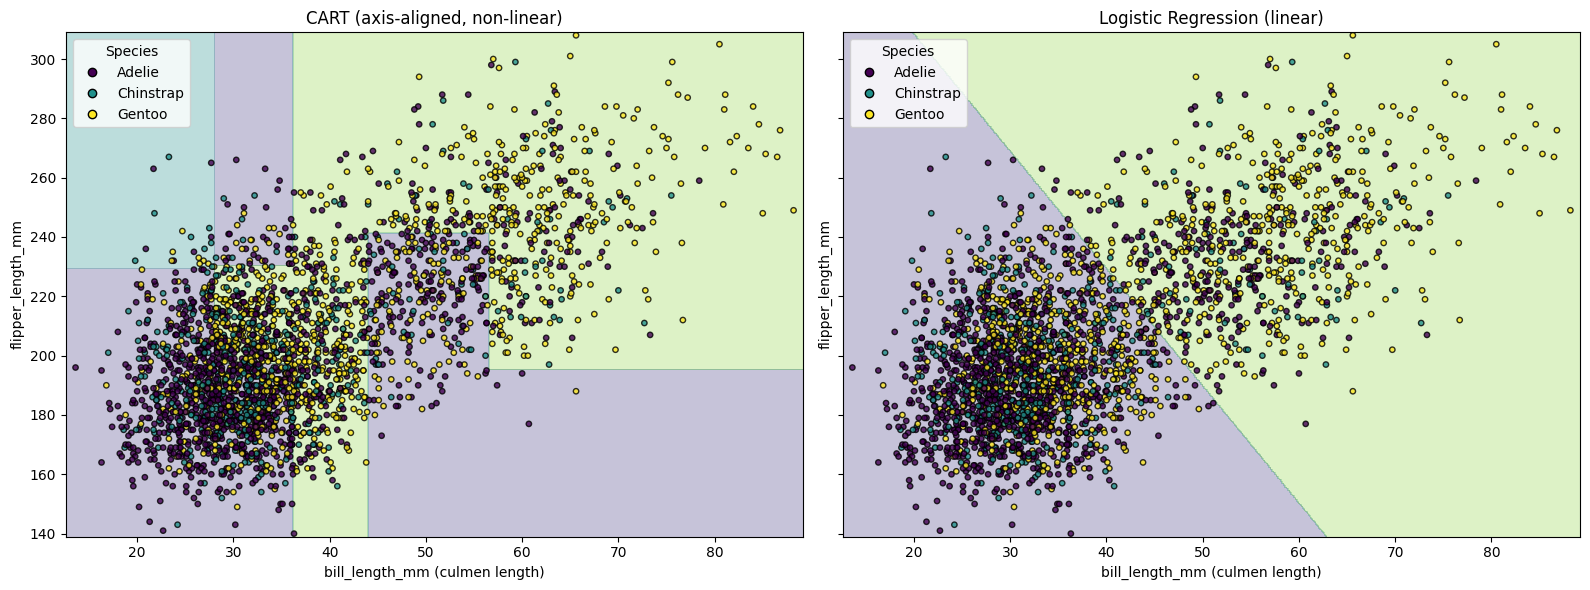

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
plot_boundary(cart2, X2_train, y2_train, axes[0], "CART (axis-aligned, non-linear)")
plot_boundary(logreg, X2_train, y2_train, axes[1], "Logistic Regression (linear)")
plt.tight_layout()
plt.show()

**Observation (Task 8):** CART splits the feature space into axis-aligned rectangles (each split is a threshold on one feature), so its regions are piecewise and can wrap around clusters. Logistic Regression draws straight lines (hyperplanes) that cut the plane into three half-plane regions. In this dataset the species overlap heavily (the extended data also contains chicks and juveniles), so neither boundary separates the classes cleanly, and Chinstrap is almost never predicted by either model.

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

Accuracy  CART (2-D)               : 0.5131
Accuracy  Logistic Regression (2-D): 0.5262

CART (2-D) Classification Report
              precision    recall  f1-score   support

      Adelie       0.54      0.62      0.57       312
   Chinstrap       0.33      0.01      0.02       125
      Gentoo       0.49      0.64      0.55       249

    accuracy                           0.51       686
   macro avg       0.45      0.42      0.38       686
weighted avg       0.48      0.51      0.46       686

Logistic Regression (2-D) Classification Report
              precision    recall  f1-score   support

      Adelie       0.51      0.79      0.62       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.56      0.47      0.51       249

    accuracy                           0.53       686
   macro avg       0.36      0.42      0.38       686
weighted avg       0.44      0.53      0.47       686



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


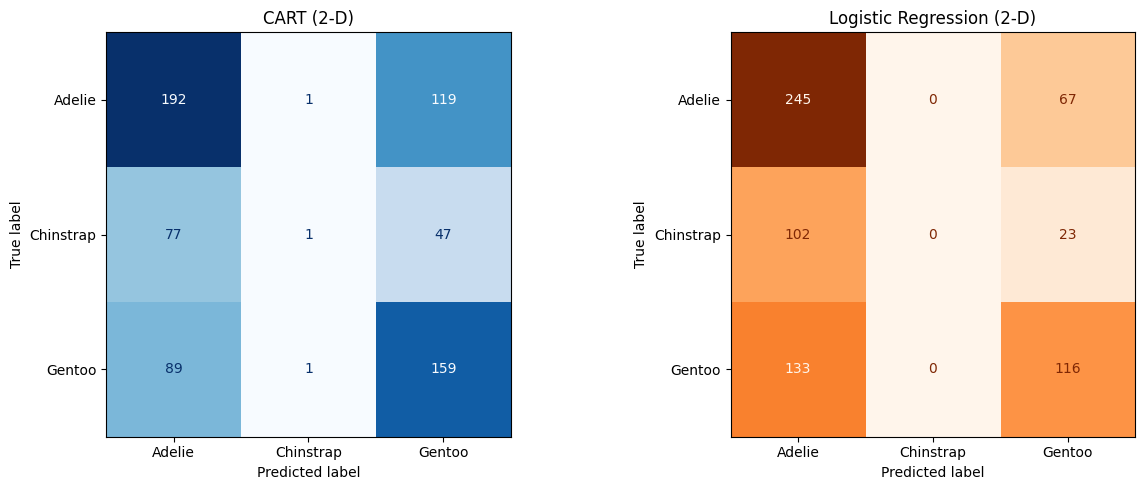

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,CART (2-D),0.5131,0.4530,0.4206,0.3809
1,Logistic Regression (2-D),0.5262,0.3578,0.4170,0.3762


In [19]:
# Fair comparison: both models use the same 2 features and the same split
y_pred_cart2 = cart2.predict(X2_test)
acc_cart2 = accuracy_score(y2_test, y_pred_cart2)
acc_lr2 = accuracy_score(y2_test, y_pred_lr)

print(f"Accuracy  CART (2-D)               : {acc_cart2:.4f}")
print(f"Accuracy  Logistic Regression (2-D): {acc_lr2:.4f}")

print("\n" + "=" * 60 + "\nCART (2-D) Classification Report\n" + "=" * 60)
print(classification_report(y2_test, y_pred_cart2, target_names=class_names))
print("=" * 60 + "\nLogistic Regression (2-D) Classification Report\n" + "=" * 60)
print(classification_report(y2_test, y_pred_lr, target_names=class_names))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y2_test, y_pred_cart2), display_labels=class_names).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("CART (2-D)")
ConfusionMatrixDisplay(confusion_matrix(y2_test, y_pred_lr), display_labels=class_names).plot(ax=axes[1], cmap="Oranges", colorbar=False)
axes[1].set_title("Logistic Regression (2-D)")
plt.tight_layout()
plt.show()

# Summary table (macro-averaged metrics)
from sklearn.metrics import precision_recall_fscore_support
rows = []
for name, pred in [("CART (2-D)", y_pred_cart2), ("Logistic Regression (2-D)", y_pred_lr)]:
    p, r, f, _ = precision_recall_fscore_support(y2_test, pred, average="macro", zero_division=0)
    rows.append([name, accuracy_score(y2_test, pred), p, r, f])
summary = pd.DataFrame(rows, columns=["Model", "Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]).round(4)
display(summary)

**Observation (Task 9):** Using the same two features and split, CART reached about 0.513 accuracy and Logistic Regression about 0.526, so the two are nearly equal. CART has higher macro precision (0.45 vs 0.36) while macro F1 is essentially the same (0.38 vs 0.38); both fail on the Chinstrap class (recall close to 0), which drives the low macro scores. Using all four features raised CART accuracy to about 0.567 (Task 5), showing that bill_depth_mm and body_mass_g carry extra information beyond bill length and flipper length. Pruning (max_depth=4) helped: the fully grown tree overfits and scores only about 0.45.

# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.